# Studio 2 — Riwayat dan Analisis Eksperimen

Deep Learning (IF25-40401) · Teknik Informatika ITERA · Semester Ganjil 2026/2027
**Kelompok:** 11 (YOLO)

Notebook ini merangkum rangkaian percobaan kelompok: apa yang dicoba, apa yang diubah, dan apa
hasilnya. Seluruh angka di dalamnya diukur dengan `evaluate.py` resmi pada **split validasi beku
yang sama**, yaitu 413 gambar dengan seed 42 dan hash kanonik
`36bee95ec932553bd3bf89d8eabe8c1d562d1343f65a442235c1df403be7a423` (`splits/val.txt`). Karena
split tersebut tidak pernah berubah, angka antar-percobaan dapat dibandingkan secara langsung.

Sel-sel kode pada notebook ini membaca berkas riwayat pelatihan yang asli di `runs/<tag>/`,
sehingga angkanya dapat diperiksa ulang, bukan sekadar diketik manual.


## 0. Cara membaca angka pada notebook ini

| Butir | Keterangan |
|---|---|
| Metrik penilaian | **Macro-F1**, yaitu rata-rata F1 kelima kelas. Setiap kelas berbobot sama, sehingga `kertas_kardus` (365 gambar) dihitung setara dengan kelas besar |
| Pembanding | Baseline asisten: ResNet-18 pretrained ≈ **0,92** pada validation set tersembunyi (±740 gambar). Angka ini **tidak dapat dibandingkan 1:1** karena himpunannya berbeda |
| Ambang noise | Split lokal berisi 413 gambar, sehingga satu gambar bernilai ±0,0024 poin. Selisih **di bawah ±0,01 belum dapat dipercaya** sebagai perbaikan |
| Pemilihan bobot | Yang disimpan adalah bobot dengan **macro-F1 validasi terbaik**, bukan epoch terakhir |
| Sumber angka | `runs/exp3_effnetv2s/`, `runs/exp4_convnext/` (berkas `history.json` dan `metrics.json`), serta arsip grafik di `docs/kurva/` |

Susunan dataset yang dipakai: 2.753 gambar. Split validasi beku berisi 413 gambar
(botol_plastik 78 · gelas_plastik 78 · kertas_kardus 55 · saset_kemasan 101 · styrofoam 101),
sedangkan 2.340 gambar sisanya dipakai untuk melatih.


## 1. Ringkasan empat percobaan

| Percobaan | Backbone | Crop | Augmentasi | lr / wd | batch | Epoch | Epoch terbaik | Macro-F1 | Akurasi | Salah | Catatan |
|---|---|---|---|---|---|---|---|---|---|---|---|
| eksperimen 1 | EfficientNetV2-S | 288 | standar | 3e-4 / 1e-4 | — | 12 | 3 | 0,9555 | 0,9564 | 18 | val loss melonjak mulai epoch 6 (overfitting) |
| eksperimen 2 | EfficientNetV2-S | 288 | strong | 1,5e-4 / 1e-2 | 32 | 12 | 9 | 0,9590 | 0,9613 | 16 | dijalankan di Colab, val loss stabil |
| eksperimen 3 | EfficientNetV2-S | 288 | strong | 1,5e-4 / 1e-2 | 32 | 11 | 7 | 0,9595 | 0,9613 | 16 | lokal; selisih terhadap eksperimen 2 adalah noise |
| eksperimen 4 | ConvNeXt-Tiny | 224 | strong | 1e-4 / 1e-2 | 16 | 20 → 9 | 5 | **0,9658** | 0,9685 | 13 | **submission saat ini** |

Dua catatan mengenai kelengkapan tabel ini:

1. Kolom `batch` untuk eksperimen 1 tidak terekam karena pada saat itu `train.py` belum menuliskan
   argumennya ke berkas riwayat. Nilai untuk eksperimen 3 mengikuti eksperimen 2, sesuai catatan
   eksperimen yang menyatakan kedua konfigurasi tersebut sama dan hanya berbeda tempat menjalankannya.
2. Eksperimen 1 pernah tercatat sebagai "3 epoch". Pencatatan yang benar adalah pelatihannya
   berjalan 12 epoch dengan **rekor pada epoch 3**, lalu val loss melonjak pada epoch 6. Angka
   0,9555 memang berasal dari epoch 3.


## 2. Eksperimen 1 — EfficientNetV2-S dengan augmentasi standar

**Pertanyaan.** Sejauh mana backbone pretrained konvensional dapat membawa hasil?

**Konfigurasi.** EfficientNetV2-S dengan crop 288, augmentasi standar, lr 3e-4, weight decay 1e-4,
12 epoch.

**Hasil.** Macro-F1 0,9555; akurasi 0,9564; 18 gambar salah. Rekor tercatat pada epoch 3.

**Analisis.** Inilah contoh overfitting yang paling jelas dalam rangkaian ini. `train_loss` terus
menurun (0,50 → 0,42) sementara `val_loss` melonjak tajam pada epoch 6 (0,50 → 1,42). Model mulai
menghafal data latih dan kehilangan kemampuan generalisasi; karena itu rekor terbaik justru
tercatat sebelum lonjakan tersebut.

Grafik arsip (nama berkas tidak menyebut nomor percobaan, sehingga disalin apa adanya):
![kurva arsip eksperimen awal](../docs/kurva/kurva_experimen_awal.png)


## 3. Eksperimen 2 — pengendalian overfitting

**Pertanyaan.** Faktor mana yang paling menentukan: augmentasi atau jadwal learning rate?

**Perubahan.** Tiga hal diubah sekaligus:

1. **Augmentasi kuat**, yaitu RandomResizedCrop 0,5–1,0, flip vertikal, RandAugment(2, 9), dan
   RandomErasing p=0,25. Model dipaksa mempelajari invarian (rotasi, pemotongan, warna, oklusi)
   alih-alih menghafal piksel tertentu.
2. **Weight decay dinaikkan dari 1e-4 menjadi 1e-2**, untuk menahan magnitudo bobot.
3. **Learning rate diturunkan dari 3e-4 menjadi 1,5e-4**, karena lr yang terlalu besar turut
   memicu lonjakan val loss pada eksperimen 1.

**Hasil.** Macro-F1 0,9590 (naik 0,0035); akurasi 0,9613; jumlah gambar salah turun dari 18 menjadi
16. `val_loss` bertahan pada kisaran 0,49–0,50 sepanjang 12 epoch tanpa lonjakan.

Grafik arsip:
![kurva eksperimen 2](../docs/kurva/kurva_exp2_effnetv2s.png)


## 4. Eksperimen 3 — pengulangan di lingkungan lokal

**Pertanyaan.** Apakah hasil eksperimen 2 dapat dipercaya, atau hanya kebetulan pada lingkungan Colab?

**Tindakan.** Konfigurasi identik dengan eksperimen 2, dijalankan pada laptop (GPU 4 GB) dengan
urutan augmentasi acak yang berbeda.

**Hasil.** Macro-F1 0,9595 berbanding 0,9590, yaitu selisih **0,0005** atau sekitar seperlima nilai
satu gambar. Selisih sebesar itu adalah noise, bukan perbaikan. Kesimpulannya penting untuk metode:
menjalankan ulang konfigurasi yang sama sudah cukup menggeser hasil beberapa per seribu, sehingga
kenaikan di bawah ±0,01 tidak layak diklaim sebagai kemajuan.

Catatan teknis: eksperimen 3 memerlukan rata-rata **511 detik per epoch** pada GPU 4 GB, sedangkan
eksperimen 4 (crop 224) hanya 116 detik. EfficientNetV2-S pada crop 288 memang sekitar empat kali
lebih berat.


## 5. Eksperimen 4 — penggantian backbone ke ConvNeXt-Tiny

**Pertanyaan.** Dari mana kenaikan berikutnya berasal: resolusi input atau kualitas backbone?

**Perubahan.** Backbone EfficientNetV2-S diganti menjadi **ConvNeXt-Tiny** (28 juta parameter),
crop diturunkan dari 288 menjadi **224**, lr 1e-4, batch 16, augmentasi strong, 20 epoch dengan
patience 5.

**Hasil.** Macro-F1 **0,9658** (naik 0,0063 dari rekor sebelumnya); akurasi 0,9685; jumlah gambar
salah turun dari 16 menjadi 13.

**Analisis.** ConvNeXt-Tiny menang meskipun diuji pada resolusi yang lebih kecil. Artinya untuk
kasus ini kualitas representasi backbone lebih menentukan daripada ukuran citra masukan.
ConvNeXt-Tiny adalah "ResNet yang dimodernisasi" dengan depthwise convolution, inverted bottleneck,
LayerNorm, dan GELU, sedangkan EfficientNetV2-S dioptimalkan untuk efisiensi FLOPs dan bukan
akurasi puncak.

**Peran early stopping.** Rekor pada percobaan ini jatuh di **epoch 5**, lalu `val_loss` terus naik
(0,4663 → 0,4837 → 0,4957) walaupun `train_loss` masih menurun. Bila yang diambil adalah bobot epoch
terakhir (epoch 9), skornya lebih rendah daripada 0,9658. Karena itu `train.py` menyimpan bobot
hanya pada saat macro-F1 membaik.


In [1]:
import json
import pathlib


def cari_root():
    """Cari root repositori (memiliki train.py dan submission/) dari lokasi notebook dijalankan."""
    p = pathlib.Path.cwd().resolve()
    for _ in range(5):
        if (p / "train.py").is_file() and (p / "submission").is_dir():
            return p
        p = p.parent
    raise SystemExit("Root repositori tidak ditemukan; jalankan notebook dari dalam folder repositori.")


ROOT = cari_root()
print("Root repositori:", ROOT)

CLASSES = ["botol_plastik", "gelas_plastik", "kertas_kardus", "saset_kemasan", "styrofoam"]

hist3 = json.loads((ROOT / "runs" / "exp3_effnetv2s" / "history.json").read_text(encoding="utf-8"))
hist4 = json.loads((ROOT / "runs" / "exp4_convnext" / "history.json").read_text(encoding="utf-8"))
met3 = json.loads((ROOT / "runs" / "exp3_effnetv2s" / "metrics.json").read_text(encoding="utf-8"))
met4 = json.loads((ROOT / "runs" / "exp4_convnext" / "metrics.json").read_text(encoding="utf-8"))


def ringkas(hist, nama):
    """Ringkas satu berkas riwayat menjadi satu baris pembanding."""
    best = max(hist, key=lambda h: h["val_macro_f1"])
    return dict(nama=nama, epoch=len(hist), best_ep=best["epoch"],
                best_f1=best["val_macro_f1"], best_acc=best["val_acc"],
                detik=sum(h["detik"] for h in hist) / len(hist), hist=hist)


r3 = ringkas(hist3, "eksperimen 3  EfficientNetV2-S @288")
r4 = ringkas(hist4, "eksperimen 4  ConvNeXt-Tiny @224")

print()
print("%-38s %6s %9s %10s %9s %12s" % ("percobaan", "epoch", "best ep", "macro-F1", "akurasi", "detik/epoch"))
print("-" * 88)
for r in (r3, r4):
    print("%-38s %6d %9d %10.4f %9.4f %12.1f" % (r["nama"], r["epoch"], r["best_ep"],
                                                 r["best_f1"], r["best_acc"], r["detik"]))
print()
print("Selisih macro-F1 eksperimen 4 terhadap eksperimen 3: %+.4f (nilai satu gambar = 0,0024)"
      % (r4["best_f1"] - r3["best_f1"]))
print()
print("Riwayat epoch eksperimen 4 (runs/exp4_convnext/history.json):")
print("%3s %10s %9s %9s %8s  %s" % ("Ep", "TrainLoss", "ValLoss", "MacroF1", "Acc", "Rekor"))
print("-" * 54)
for h in hist4:
    print("%3d %10.4f %9.4f %9.4f %8.4f  %s" % (h["epoch"], h["train_loss"], h["val_loss"],
                                                h["val_macro_f1"], h["val_acc"],
                                                "BEST" if h["epoch"] == r4["best_ep"] else ""))


Root repositori: D:\Perkuliahan duniawi\Semester 7\Pembelajaran Mendalam\Tugas studio 2\DL-RA_studio2-klasifikasi-sampah

percobaan                               epoch   best ep   macro-F1   akurasi  detik/epoch
----------------------------------------------------------------------------------------
eksperimen 3  EfficientNetV2-S @288        11         7     0.9595    0.9613        511.1
eksperimen 4  ConvNeXt-Tiny @224            9         5     0.9658    0.9685        116.4

Selisih macro-F1 eksperimen 4 terhadap eksperimen 3: +0.0063 (nilai satu gambar = 0,0024)

Riwayat epoch eksperimen 4 (runs/exp4_convnext/history.json):
 Ep  TrainLoss   ValLoss   MacroF1      Acc  Rekor
------------------------------------------------------
  1     0.7771    0.5256    0.9431   0.9467  
  2     0.5250    0.5012    0.9532   0.9564  
  3     0.4715    0.4875    0.9613   0.9637  
  4     0.4541    0.5042    0.9484   0.9516  
  5     0.4408    0.4663    0.9658   0.9685  BEST
  6     0.4377    0.4837 

Grafik disimpan pada: D:\Perkuliahan duniawi\Semester 7\Pembelajaran Mendalam\Tugas studio 2\DL-RA_studio2-klasifikasi-sampah\docs\riwayat_eksperimen.png


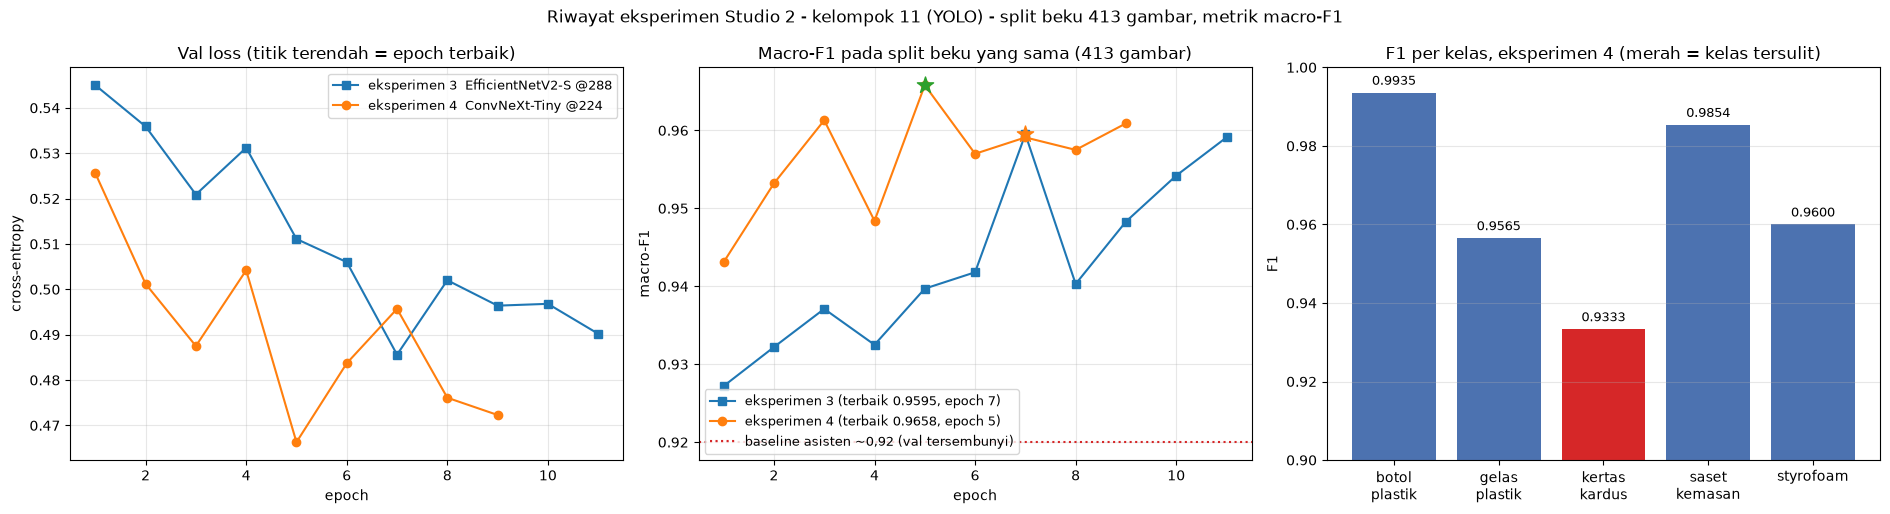

In [2]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))

# Panel 1 — val loss
ax[0].plot([h["epoch"] for h in hist3], [h["val_loss"] for h in hist3], "s-",
           label="eksperimen 3  EfficientNetV2-S @288")
ax[0].plot([h["epoch"] for h in hist4], [h["val_loss"] for h in hist4], "o-",
           label="eksperimen 4  ConvNeXt-Tiny @224")
ax[0].set_title("Val loss (titik terendah = epoch terbaik)")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("cross-entropy")
ax[0].legend(fontsize=9); ax[0].grid(alpha=0.3); ax[0].xaxis.set_major_locator(MaxNLocator(integer=True))

# Panel 2 — macro-F1
ax[1].plot([h["epoch"] for h in hist3], [h["val_macro_f1"] for h in hist3], "s-",
           label="eksperimen 3 (terbaik %.4f, epoch %d)" % (r3["best_f1"], r3["best_ep"]))
ax[1].plot([h["epoch"] for h in hist4], [h["val_macro_f1"] for h in hist4], "o-",
           label="eksperimen 4 (terbaik %.4f, epoch %d)" % (r4["best_f1"], r4["best_ep"]))
ax[1].axhline(0.92, color="#d62728", ls=":", lw=1.5, label="baseline asisten ~0,92 (val tersembunyi)")
ax[1].scatter([r3["best_ep"]], [r3["best_f1"]], s=150, marker="*", color="#ff7f0e", zorder=5)
ax[1].scatter([r4["best_ep"]], [r4["best_f1"]], s=150, marker="*", color="#2ca02c", zorder=5)
ax[1].set_title("Macro-F1 pada split beku yang sama (413 gambar)")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("macro-F1")
ax[1].legend(fontsize=9); ax[1].grid(alpha=0.3); ax[1].xaxis.set_major_locator(MaxNLocator(integer=True))

# Panel 3 — F1 per kelas eksperimen 4
pc = met4["per_class_f1"]
nama = [c.replace("_", "\n") for c in CLASSES]
nilai = [pc[c] for c in CLASSES]
warna = ["#d62728" if c == "kertas_kardus" else "#4c72b0" for c in CLASSES]
bar = ax[2].bar(nama, nilai, color=warna)
ax[2].set_ylim(0.90, 1.0)
ax[2].set_title("F1 per kelas, eksperimen 4 (merah = kelas tersulit)")
ax[2].set_ylabel("F1")
for b, v in zip(bar, nilai):
    ax[2].text(b.get_x() + b.get_width() / 2, v + 0.002, "%.4f" % v, ha="center", fontsize=9)
ax[2].grid(alpha=0.3, axis="y")

fig.suptitle("Riwayat eksperimen Studio 2 - kelompok 11 (YOLO) - split beku 413 gambar, metrik macro-F1")
fig.tight_layout()

keluar = ROOT / "docs" / "riwayat_eksperimen.png"
fig.savefig(keluar, dpi=150, bbox_inches="tight")
print("Grafik disimpan pada:", keluar)
plt.show()


## 6. F1 per kelas dan penyebab `kertas_kardus` selalu terlemah

| Kelas | Jumlah gambar latih | F1 eksperimen 4 |
|---|---|---|
| botol_plastik | 523 | 0,9935 |
| gelas_plastik | 521 | 0,9565 |
| **kertas_kardus** | **365** | **0,9333** |
| saset_kemasan | 673 | 0,9854 |
| styrofoam | 671 | 0,9600 |

Terdapat dua penyebab, dan keduanya tampak pada data:

1. **Ketidakseimbangan kelas.** `kertas_kardus` hanya berisi 365 gambar, paling sedikit di antara
   kelima kelas, sehingga paling jarang dilihat model.
2. **Kemiripan visual.** Kertas dan kardus berwarna terang bertekstur mudah tertukar dengan
   styrofoam dan gelas plastik. Pada confusion matrix eksperimen 4, dari 55 gambar `kertas_kardus`
   terdapat 5 gambar yang meleset (3 ke gelas_plastik, 1 ke saset, 2 ke styrofoam), dan `styrofoam`
   juga meleset 5 kali.

Hal inilah yang menjadikan macro-F1 sebagai metrik penilaian, bukan akurasi. Akurasi akan condong
ke kelas mayoritas (saset dan styrofoam), sedangkan macro-F1 memberi setiap kelas bobot yang sama.

Perbandingan antar-backbone pada kelas ini juga informatif: EfficientNetV2-S (eksperimen 2) memperoleh
F1 0,9273 dan ConvNeXt-Tiny menaikkannya menjadi 0,9333, sedangkan kelas lain naik jauh lebih besar
(botol_plastik 0,9747 → 0,9935; saset_kemasan 0,9600 → 0,9854). Perbaikan backbone justru paling
sedikit terasa pada kelas tersulit, yang menandakan batasnya terletak pada data dan bukan pada
arsitektur.


## 7. Penyimpanan bobot dalam fp16 (106 MB → 53 MB)

ConvNeXt-Tiny dalam fp32 berukuran **106,2 MB**, sedangkan GitHub **menolak** berkas di atas 100 MB.
Karena itu `submission/model.pth` disimpan dalam **fp16**, yaitu `state_dict` yang dibulatkan ke
setengah presisi.

Dasar keamanan konversi tersebut:

| Pemeriksaan | Hasil |
|---|---|
| Seluruh tensor berupa float (tanpa `num_batches_tracked`) | ya; 182 tensor, 27.823.973 parameter |
| Error relatif maksimum bobot | 4,880e-04, tepat 2^-11 atau batas presisi fp16 |
| `strict=True` pada `evaluate.py` | lolos, tanpa kunci `missing` maupun `unexpected` |
| Macro-F1 fp32 berbanding fp16 pada 413 gambar | **0,9658 berbanding 0,9658** (identik) |
| Confusion matrix | identik sel per sel; 0 prediksi berubah |
| Waktu evaluasi (CPU 2 inti) | 24,7 detik; untuk 740 gambar tersembunyi sekitar 45 detik, jauh di bawah batas 15 menit |

Sel berikut memverifikasi ulang berkas `submission/model.pth` yang ada di repositori.


In [3]:
import hashlib

import torch

sub = ROOT / "submission" / "model.pth"
sd = torch.load(sub, map_location="cpu", weights_only=True)

print("Berkas   :", sub)
print("Ukuran   : %.1f MB (%s byte)" % (sub.stat().st_size / 2 ** 20, format(sub.stat().st_size, ",")))
print("sha256   :", hashlib.sha256(sub.read_bytes()).hexdigest()[:16], "...")
print("dtype    :", next(iter(sd.values())).dtype)
print("Tensor   :", len(sd), "| parameter:", format(sum(v.numel() for v in sd.values()), ","))
print("Batas    : 100 MB GitHub ->", "aman" if sub.stat().st_size < 100 * 2 ** 20 else "bermasalah")
print("Non-float:", [k for k, v in sd.items() if not v.is_floating_point()] or "tidak ada")

# Bukti kontrak: muat ke arsitektur dari submission/model.py dengan strict=True
import importlib.util
import sys

spec = importlib.util.spec_from_file_location("sub_model", ROOT / "submission" / "model.py")
mod = importlib.util.module_from_spec(spec)
sys.path.insert(0, str(ROOT / "submission"))
spec.loader.exec_module(mod)

model = mod.get_model()
model.load_state_dict(sd, strict=True)
model.eval()
with torch.no_grad():
    out = model(torch.zeros(2, 3, 224, 224))
print("strict load dan forward: OK | keluaran", tuple(out.shape), "(harus [batch, 5])")


Berkas   : D:\Perkuliahan duniawi\Semester 7\Pembelajaran Mendalam\Tugas studio 2\DL-RA_studio2-klasifikasi-sampah\submission\model.pth
Ukuran   : 53.1 MB (55,691,419 byte)
sha256   : db0ba6cc3122f578 ...
dtype    : torch.float16
Tensor   : 182 | parameter: 27,823,973
Batas    : 100 MB GitHub -> aman
Non-float: tidak ada


strict load dan forward: OK | keluaran (2, 5) (harus [batch, 5])


## 8. Cara mereproduksi setiap percobaan

Seluruh percobaan dijalankan dengan `train.py`, yang memilih checkpoint berdasarkan macro-F1 pada
split beku. Dataset diasumsikan berada di `data/train` dan tidak ikut di-commit, sesuai ketentuan
kompetisi. Berkas arsitektur kandidat berada di `experiments/`.

```bash
# eksperimen 1 — EfficientNetV2-S, augmentasi standar (mengalami overfitting)
python train.py --data data/train --model experiments/efficientnet_v2s.py   --epochs 12 --bs 32 --lr 3e-4 --wd 1e-4 --aug standard   --out runs/exp1_effnetv2s/model.pth --history-out runs/exp1_effnetv2s/history.json

# eksperimen 2 — EfficientNetV2-S, augmentasi strong dan wd 1e-2
python train.py --data data/train --model experiments/efficientnet_v2s.py   --epochs 12 --bs 32 --lr 1.5e-4 --wd 1e-2 --aug strong   --out runs/exp2_effnetv2s/model.pth --history-out runs/exp2_effnetv2s/history.json

# eksperimen 3 — sama dengan eksperimen 2, dijalankan lokal sebagai pengukuran noise
python train.py --data data/train --model experiments/efficientnet_v2s.py   --epochs 11 --bs 32 --lr 1.5e-4 --wd 1e-2 --aug strong   --out runs/exp3_effnetv2s/model.pth --history-out runs/exp3_effnetv2s/history.json

# eksperimen 4 — ConvNeXt-Tiny crop 224 (pemenang, submission saat ini)
python train.py --data data/train --model experiments/convnext_tiny.py   --epochs 20 --bs 16 --lr 1e-4 --wd 1e-2 --aug strong --patience 5   --out runs/exp4_convnext/model.pth --history-out runs/exp4_convnext/history.json

# selalu diakhiri dengan penilai resmi pada split beku yang sama
python evaluate.py --submission ./submission --data ./my_val
```

Pada eksperimen 2 dan 3, berkas arsitektur yang dipakai adalah `submission/model.py` karena pada
saat itu berkas tersebut masih berisi definisi EfficientNetV2-S. Mulai eksperimen 4, arsitektur
dipisahkan ke folder `experiments/` agar berkas submission tidak berubah setiap kali ada percobaan
baru. Isi keduanya identik dan sudah disalin ke `experiments/efficientnet_v2s.py`.


## 9. Kesimpulan dan rencana berikutnya

**Tiga temuan yang terbukti dari rangkaian percobaan ini:**

1. **Overfitting, bukan kekurangan kapasitas, merupakan masalah utama.** Eksperimen 1
   membuktikannya (val loss melonjak pada epoch 6), dan urutan pengendalian termurah berhasil:
   augmentasi strong, kemudian menaikkan weight decay, lalu menurunkan learning rate.
2. **Kualitas backbone lebih menentukan daripada resolusi input.** ConvNeXt-Tiny pada crop 224
   mengungguli EfficientNetV2-S pada crop 288.
3. **Pemilihan checkpoint harus mengikuti macro-F1, bukan akurasi maupun epoch terakhir.** Rekor
   eksperimen 4 jatuh pada epoch 5 dari 9, dan melatih lebih lama tidak menambah skor.

**Rencana untuk putaran Preview 2 dan Final, diurutkan dari yang paling murah:**

1. Menaikkan resolusi ConvNeXt-Tiny dari 224 menjadi 288 atau 320; backbone ini masih memiliki ruang.
2. Memperbaiki kelas `kertas_kardus` melalui class-weighted loss atau pengambilan sampel berlebih
   untuk kelas minoritas (365 gambar). Karena setiap kelas menyumbang 1/5 dari macro-F1, mengangkat
   kelas terlemah memberi dampak terbesar.
3. Model soup, yaitu merata-ratakan bobot beberapa epoch puncak eksperimen 4, tanpa tambahan biaya
   inferensi.
4. Test-time augmentation berupa flip horizontal saat inferensi; sah menurut kontrak submission dan
   waktu evaluasinya masih jauh di bawah batas 15 menit.
5. Ensemble dua backbone (ConvNeXt dan EfficientNetV2-S) sebagai upaya terakhir.

**Cara memilih model pada putaran berikutnya.** Bandingkan selalu dengan 0,9658 pada split beku yang
sama, dan klaim perbaikan hanya bila selisihnya melebihi ±0,01.

**Inventaris bukti pekerjaan pada repositori ini:**

| Artefak | Isi |
|---|---|
| `runs/exp3_effnetv2s/`, `runs/exp4_convnext/` | `history.json` (riwayat per epoch), `metrics.json` (ringkasan hasil, F1 per kelas, confusion matrix), `curves.png` |
| `docs/kurva/` | Arsip grafik dari percobaan awal |
| `docs/ANALISIS_EKSPERIMEN.md` | Analisis naratif hasil percobaan |
| `notebooks/percobaan_convnext.ipynb` | Prosedur menjalankan ulang percobaan ConvNeXt-Tiny di Google Colab |
| `notebooks/percobaan_effnetv2s.ipynb` | Prosedur menjalankan ulang percobaan EfficientNetV2-S di Google Colab |
